# Markov switching com trend following

- Primeiramente iremos escolher as acoes que iremos utilizar. Utilizaremos as ações que tem melhor relacao entre drift e volatilidade. Sendo importante para o nosso modelo, essa relação para poder identificar uma possivel tendencia

- Para evitar look ahead bias, iremos utilizar dados de 2010 - 2018 para treino e dados de 2019 a 2026 como teste

In [85]:
import numpy as np
import pandas as pd
import yfinance as yf

# Grandes empresas da B3 no início de 2010 (tickers atuais no Yahoo).

empresas_brasileiras = [
    "PETR4", "VALE3", "ITUB4", "BBDC4", "BBAS3", "ABEV3", "ITSA4", "B3SA3",
    "GGBR4", "CSNA3", "USIM5", "VIVT3", "CMIG4", "SBSP3", "CPFE3",
    "PCAR3", "TIMS3", "WEGE3", "LREN3", "SUZB3", "RENT3",
]
tickers = [t + ".SA" for t in empresas_brasileiras]
# Só o período de treino
precos = yf.download(tickers, start="2010-01-01", end="2018-12-31",
                     auto_adjust=True, progress=False)["Close"]

# Remove ações sem histórico suficiente (exige 90% dos dias com dado)
cobertura = precos.notna().mean()
removidas = cobertura[cobertura < 0.9].index.tolist()
if removidas:
    print("Removidas por falta de dados:", removidas)
precos = precos.drop(columns=removidas)

# Drift e volatilidade anualizados (retornos log)
retornos = np.log(precos).diff()
drift = retornos.mean() * 252
vol = retornos.std() * np.sqrt(252)

ranking = pd.DataFrame({"drift": drift, "vol": vol, "mu/sigma": drift / vol})
ranking = ranking.sort_values("mu/sigma", ascending=False)

selecionados = ranking.head(3).index.tolist()
display(ranking)
print("Selecionados:", selecionados)

,drift,vol,mu/sigma
Ticker,,,
LREN3.SA,0.221326,0.325009,0.680984
ABEV3.SA,0.143958,0.228541,0.629901
RENT3.SA,0.201483,0.340854,0.591110
SUZB3.SA,0.108487,0.185125,0.586019
WEGE3.SA,0.155859,0.272945,0.571029
SBSP3.SA,0.154166,0.333481,0.462294
ITUB4.SA,0.116569,0.301764,0.386291
ITSA4.SA,0.114196,0.300913,0.379498
CPFE3.SA,0.093825,0.262790,0.357034


Selecionados: ['LREN3.SA', 'ABEV3.SA', 'RENT3.SA']


In [86]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from bcb import sgs                      # pip install python-bcb

tickers = ["LREN3.SA", "ABEV3.SA", "RENT3.SA"]
date_from = "2010-01-01"
date_to = "2026-07-31"

prices = {}
for ticker in tickers:
    prices[ticker] = yf.download(ticker, start=date_from, end=date_to, interval='1d', auto_adjust=True)
    prices[ticker] = prices[ticker].droplevel(1, axis=1)

# CDI diário do Banco Central (série 12 do SGS, em % ao dia)
# A API aceita no máximo 10 anos por consulta, então baixamos em dois blocos
blocos = [(date_from, "2017-12-31"), ("2018-01-01", date_to)]
cdi_dia = pd.concat([sgs.get({"cdi": 12}, start=ini, end=fim) for ini, fim in blocos])["cdi"] / 100
cdi_dia = cdi_dia[~cdi_dia.index.duplicated()]
cdi_anual = (1 + cdi_dia) ** 252 - 1

CDI = 100 * cdi_anual.loc["2019":].mean()   # média do período de teste (% a.a.), usada no Sharpe
print(f"CDI médio no teste: {CDI:.2f}% a.a.")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


CDI médio no teste: 9.55% a.a.


In [87]:
from scipy.optimize import minimize
from scipy.stats import t as student_t


class MarkovSwitching:

    nomes = ["p", "q", "mu", "sigma0", "sigma1", "nu"]

    def __init__(self):
        self.params_ = None
        self.res_ = None

    @staticmethod
    def hamilton_filter(y, p, q, mu, sigma0, sigma1, nu=np.inf):
        y = np.asarray(y, dtype=float)
        T = len(y)

        f1 = student_t.pdf(y, df=nu, loc=mu, scale=sigma1)
        f0 = student_t.pdf(y, df=nu, loc=mu, scale=sigma0)

        xi = np.empty(T)
        loglik = 0.0
        xi_prev = (1 - q) / (2 - p - q)

        for t in range(T):
            prior1 = p * xi_prev + (1 - q) * (1 - xi_prev)

            num1 = f1[t] * prior1
            dens = num1 + f0[t] * (1 - prior1)
            xi[t] = num1 / dens

            loglik += np.log(dens)
            xi_prev = xi[t]

        return xi, loglik

    @staticmethod
    def unpack(theta):
        p = 1 / (1 + np.exp(-theta[0]))
        q = 1 / (1 + np.exp(-theta[1]))
        mu = theta[2]
        sigma0 = np.exp(theta[3])
        sigma1 = sigma0 * (1 + np.exp(theta[4]))
        nu = 2 + np.exp(theta[5])
        return p, q, mu, sigma0, sigma1, nu

    def neg_loglik(self, theta, y):
        return -self.hamilton_filter(y, *self.unpack(theta))[1]

    def fit(self, y):
        y = np.asarray(y, dtype=float)
        s = y.std()
        theta0 = np.array([3.0, 3.0, y.mean(), np.log(0.7 * s), 0.0, np.log(3.0)])
        self.res_ = minimize(self.neg_loglik, theta0, args=(y,), method="Nelder-Mead",
                             options={"maxiter": 10000, "xatol": 1e-6, "fatol": 1e-6})
        self.params_ = dict(zip(self.nomes, self.unpack(self.res_.x)))
        return self

    def filter(self, y):
        xi, _ = self.hamilton_filter(y, **self.params_)
        return pd.Series(xi, index=y.index)

In [88]:
TRAIN_END = "2018-12-31"

params_all = {}
regimes = {}

for ticker in tickers:
    close = prices[ticker]["Close"]
    r = 100 * np.log(close).diff().dropna()   # retorno log em %, como no Hamilton

    # Estima só no treino (sem olhar o futuro)
    modelo = MarkovSwitching().fit(r[:TRAIN_END])
    params_all[ticker] = modelo.params_

    # Roda o filtro na amostra toda com os parâmetros do treino
    regimes[ticker] = pd.DataFrame({"ret": r, "xi": modelo.filter(r)}, index=r.index)

# Tabela de parâmetros + métricas da Seção 2
tab = pd.DataFrame(params_all).T
tab["pi"] = (1 - tab["q"]) / (2 - tab["p"] - tab["q"])
tab["dur_alta"] = 1 / (1 - tab["p"])      # dias
tab["dur_baixa"] = 1 / (1 - tab["q"])
tab["lambda"] = tab["p"] + tab["q"] - 1
tab.round(4)

,p,q,mu,sigma0,sigma1,nu,pi,dur_alta,dur_baixa,lambda
LREN3.SA,0.9798,0.9822,0.0741,1.3971,2.3236,12.3967,0.4687,49.5881,56.2015,0.9620
ABEV3.SA,0.9956,0.9799,0.0638,0.7250,1.2361,5.6131,0.8194,225.4898,49.7045,0.9754
RENT3.SA,0.9889,0.9857,0.0838,1.4384,2.4405,24.8808,0.5629,89.9239,69.8183,0.9746


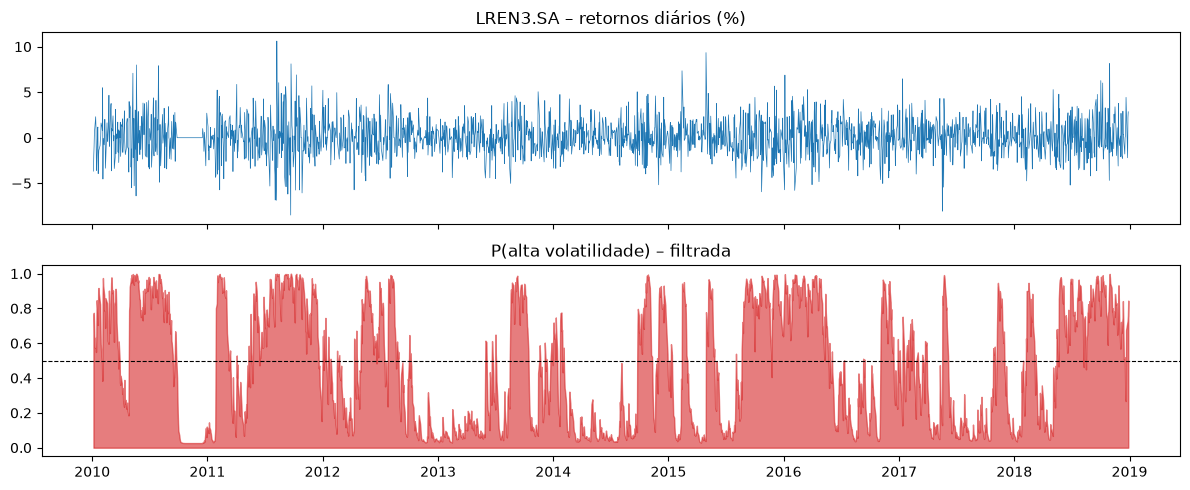

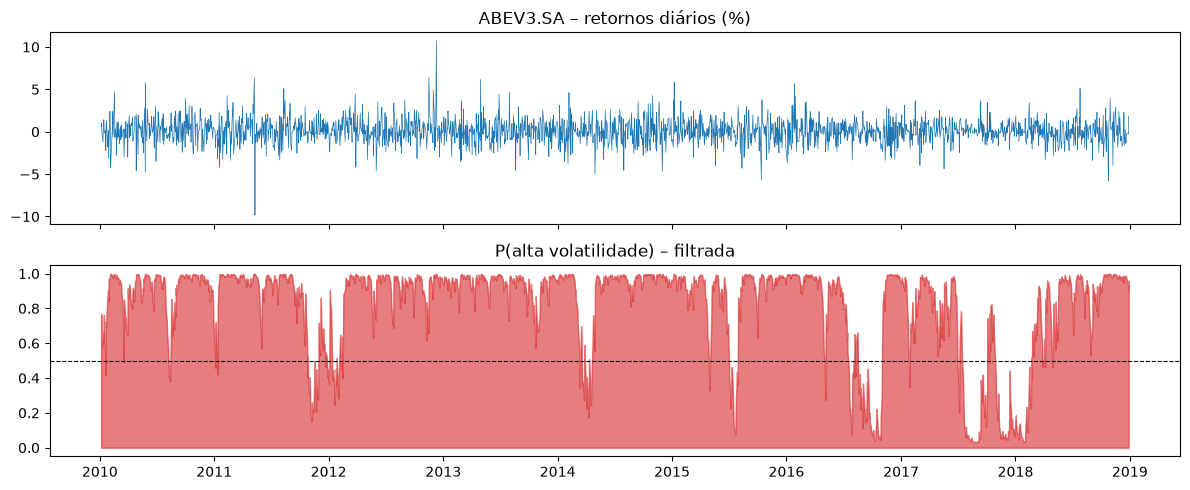

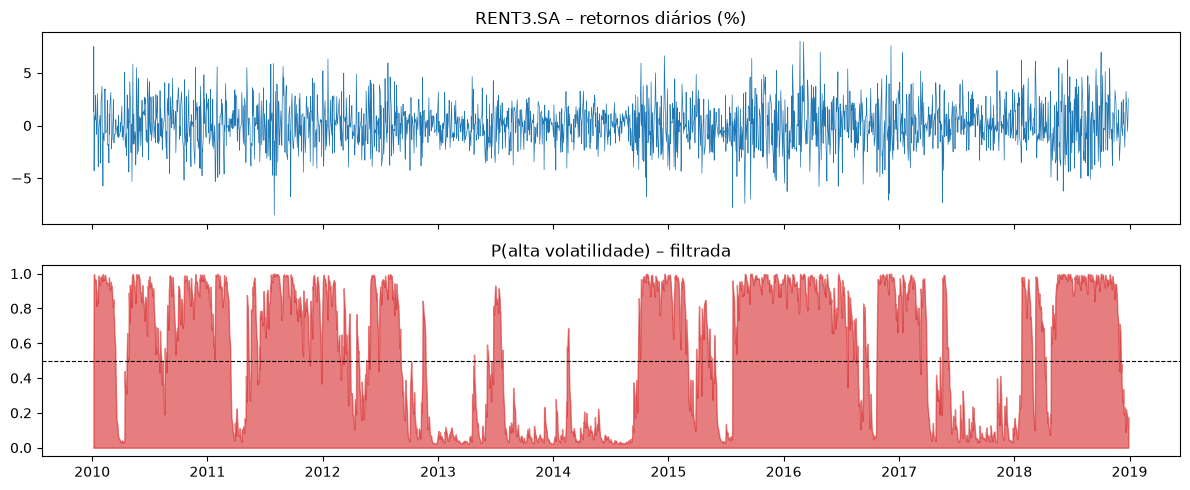

In [89]:
for ticker in tickers:
    df = regimes[ticker].loc[:TRAIN_END]
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(df.index, df["ret"], lw=0.5)
    ax[0].set_title(f"{ticker} – retornos diários (%)")
    ax[1].fill_between(df.index, df["xi"], color="tab:red", alpha=0.6)
    ax[1].axhline(0.5, color="k", ls="--", lw=0.8)
    ax[1].set_title("P(alta volatilidade) – filtrada")
    plt.tight_layout()
    plt.show()

In [90]:
import backtrader as bt

TEST_START = "2019-01-01"
LOOKBACK = 252


# Criando uma conta que rentabiliza CDI diariamente (só sobre o capital próprio):
class CarryBroker(bt.brokers.BackBroker):
    params = dict(carry=CDI/100)

    def __init__(self):
        super().__init__()

    def next(self):
        daily_carry = (1 + self.p.carry) ** (1/252) - 1
        base = max(min(self.cash, self.getvalue()), 0)
        self.cash += base * daily_carry
        super().next()


class PandasXi(bt.feeds.PandasData):
    lines = ("xi", "mom", "cdi")
    params = (("xi", -1), ("mom", -1), ("cdi", -1))


def make_data(ticker, inicio=TEST_START, fim=None):
    df = prices[ticker][["Open", "High", "Low", "Close", "Volume"]].copy()
    r = np.log(df["Close"]).diff()
    df["xi"] = regimes[ticker]["xi"].reindex(df.index).ffill()
    df["mom"] = np.sign(r.rolling(LOOKBACK).sum())
    df["cdi"] = cdi_anual.reindex(df.index).ffill()
    df = df.loc[inicio:fim].dropna()
    return PandasXi(dataname=df, name=ticker)


class RegimeTSMOM(bt.Strategy):

    params = dict(thresh=0.5, alloc=0.99)

    def __init__(self):
        self.alvo = {d: None for d in self.datas}

    def next(self):
        self.broker.p.carry = self.datas[0].cdi[0]   # atualiza o CDI do dia no broker

        peso = self.p.alloc / len(self.datas)
        for d in self.datas:
            alvo = d.mom[0] * peso if d.xi[0] < self.p.thresh else 0.0
            if alvo != self.alvo[d]:
                self.order_target_percent(data=d, target=alvo)
                self.alvo[d] = alvo


class TSMOM(RegimeTSMOM):
    params = dict(thresh=1.01)   # filtro desligado: segue sempre o sinal de tendência


class BuyHold(bt.Strategy):

    params = dict(alloc=0.99)

    def __init__(self):
        self.comprou = False

    def next(self):
        self.broker.p.carry = self.datas[0].cdi[0]   # atualiza o CDI do dia no broker

        if self.comprou:
            return
        for d in self.datas:
            self.order_target_percent(data=d, target=self.p.alloc / len(self.datas))
        self.comprou = True


# Função que faz a simulação com o report
def simulate(strategy, datas, **kwargs):

    cerebro = bt.Cerebro(stdstats=True) # Cria o Engine de simulação
    cerebro.broker = CarryBroker(carry=CDI/100)
    for d in datas:
        cerebro.adddata(d) # Adiciona os dados
    cerebro.addstrategy(strategy, **kwargs)  # Adiciona a estratégia

    CUSTO_EMOLUMENTOS = (0.005 + 0.0275) / 100  # taxa de 0.005% + 0.0275% (emolumentos)

    # Ajustando parâmetros de carteira
    cerebro.broker.setcash(1_000_000)
    cerebro.broker.setcommission(commission=CUSTO_EMOLUMENTOS)
    cerebro.broker.set_coc(True)  # cheat on close - para comprar no mesmo dia

    # Performance & Risk Metrics
    cerebro.addanalyzer(bt.analyzers.Returns, _name='returns')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.NoTimeFrame, _name='timereturn')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.Days, _name='ret_diario')
    cerebro.addanalyzer(bt.analyzers.SharpeRatio, _name='sharpe', timeframe=bt.TimeFrame.Days, riskfreerate=CDI/100, annualize=True)
    cerebro.addanalyzer(bt.analyzers.SQN, _name='sqn')  # System Quality Number
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name='drawdown')
    cerebro.addanalyzer(bt.analyzers.Calmar, _name='calmar')
    cerebro.addanalyzer(bt.analyzers.VWR, _name='vwr', timeframe=bt.TimeFrame.Days)  # Variability-Weighted Return

    # Trade
    cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='trade_analyzer')
    cerebro.addanalyzer(bt.analyzers.Transactions, _name='transactions')
    cerebro.addanalyzer(bt.analyzers.PositionsValue, _name='positions')

    # Drawdown
    cerebro.addanalyzer(bt.analyzers.TimeDrawDown, _name='timedrawdown')
    cerebro.addanalyzer(bt.analyzers.GrossLeverage, _name='leverage')

    # Portfolio Analysis
    cerebro.addanalyzer(bt.analyzers.PyFolio, _name='pyfolio')

    # Run the strategy
    results = cerebro.run()
    strat = results[0]

    # Extract and display all performance metrics
    print("=" * 60)
    print("PERFORMANCE METRICS SUMMARY")
    print("=" * 60)

    # Basic Returns (rtot é log-retorno; convertemos para retorno simples)
    returns_analyzer = strat.analyzers.returns.get_analysis()
    print(f"Total Return: {np.exp(returns_analyzer['rtot']) - 1:.2%}")
    print(f"Average Return: {returns_analyzer['ravg']:.4%}")
    print(f"Compound Annual Growth Rate: {returns_analyzer['rnorm100']:.2f}%")

    # Sharpe Ratio
    sharpe = strat.analyzers.sharpe.get_analysis()
    print(f"Sharpe Ratio: {sharpe.get('sharperatio', 'N/A'):.4f}" if sharpe.get('sharperatio') else "Sharpe Ratio: N/A")

    # System Quality Number
    sqn = strat.analyzers.sqn.get_analysis()
    print(f"System Quality Number (SQN): {sqn.get('sqn', 'N/A'):.4f}" if sqn.get('sqn') else "SQN: N/A")

    # DrawDown Analysis
    dd = strat.analyzers.drawdown.get_analysis()
    print(f"Max Drawdown: {dd.max.drawdown:.2f}%")
    print(f"Max Drawdown Duration: {dd.max.len} periods")
    print(f"Max Drawdown Money: ${dd.max.moneydown:,.2f}")

    # Calmar Ratio (Annual Return / Max Drawdown)
    calmar = strat.analyzers.calmar.get_analysis()
    print(f"Calmar Ratio: {calmar.get('calmar', 'N/A'):.4f}" if calmar.get('calmar') else "Calmar Ratio: N/A")

    # VWR - Variability-Weighted Return
    vwr = strat.analyzers.vwr.get_analysis()
    print(f"VWR: {vwr.get('vwr', 'N/A'):.4f}" if vwr.get('vwr') else "VWR: N/A")

    print("\n" + "=" * 60)
    print("TRADE ANALYSIS")
    print("=" * 60)

    # Trade Analysis
    trade_analysis = strat.analyzers.trade_analyzer.get_analysis()
    total_trades = trade_analysis.get('total', {}).get('total', 0)
    print(f"Total Trades: {total_trades}")

    if total_trades > 0:
        won = trade_analysis.get('won', {})
        lost = trade_analysis.get('lost', {})
        pnl = trade_analysis.get('pnl', {})
        length = trade_analysis.get('len', {})

        print(f"Total Open Trades: {trade_analysis.total.get('open', 0)}")
        print(f"Total Closed Trades: {trade_analysis.total.get('closed', 0)}")

        print(f"\nWinning Trades: {won.get('total', 0)}")
        print(f"Losing Trades: {lost.get('total', 0)}")
        print(f"Win Rate: {(won.get('total', 0) / total_trades) * 100:.1f}%")

        if won.get('total', 0) > 0:
            print(f"Average Win: ${won.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Win: ${won.get('pnl', {}).get('max', 0):,.2f}")

        if lost.get('total', 0) > 0:
            print(f"Average Loss: ${lost.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Loss: ${lost.get('pnl', {}).get('max', 0):,.2f}")

        print(f"Average Trade: ${pnl.get('net', {}).get('average', 0):,.2f}")
        print(f"Average Trade Length: {length.get('average', 0):.1f} periods")

        # Lucro bruto, perda bruta e Profit Factor
        gross_profit = won.get('pnl', {}).get('total', 0)
        gross_loss = abs(lost.get('pnl', {}).get('total', 0))
        print(f"\nGross Profit: ${gross_profit:,.2f}")
        print(f"Gross Loss: ${-gross_loss:,.2f}")
        print(f"Net Trading P&L: ${gross_profit - gross_loss:,.2f}")
        if gross_loss > 0:
            profit_factor = gross_profit / gross_loss
            print(f"Profit Factor: {profit_factor:.2f}")

    print("\n" + "=" * 60)
    print("PORTFOLIO VALUE")
    print("=" * 60)
    print(f"Starting Portfolio Value: $1,000,000.00")
    print(f"Final Portfolio Value: ${cerebro.broker.getvalue():,.2f}")
    print(f"Total P&L: ${cerebro.broker.getvalue() - 1_000_000:,.2f}")

    # Pyfolio
    pyfolio_analyzer = strat.analyzers.pyfolio
    returns, positions, transactions, gross_lev = pyfolio_analyzer.get_pf_items()
    print(f"\nReturns Series Length: {len(returns)}")
    print(f"Positions Tracked: {len(positions.columns) if hasattr(positions, 'columns') else 0}")
    print(f"Transactions Recorded: {len(transactions)}")

    return cerebro, strat

In [91]:
estrategias = {"buy_hold": BuyHold, "tsmom": TSMOM, "regime_tsmom": RegimeTSMOM}
resultados = {}

for t in tickers:
    for nome, estr in estrategias.items():
        print(f"\n########## {t} – {nome} ##########")
        resultados[(t, nome)] = simulate(estr, [make_data(t)])

for nome, estr in estrategias.items():
    print(f"\n########## Carteira – {nome} ##########")
    resultados[("carteira", nome)] = simulate(estr, [make_data(t) for t in tickers])


########## LREN3.SA – buy_hold ##########
PERFORMANCE METRICS SUMMARY
Total Return: -45.80%
Average Return: -0.0325%
Compound Annual Growth Rate: -7.86%
Sharpe Ratio: -0.1796
SQN: N/A
Max Drawdown: 75.64%
Max Drawdown Duration: 1622 periods
Max Drawdown Money: $1,174,383.88
Calmar Ratio: N/A
VWR: -2.6894

TRADE ANALYSIS
Total Trades: 1
Total Open Trades: 1
Total Closed Trades: 0

Winning Trades: 0
Losing Trades: 0
Win Rate: 0.0%
Average Trade: $0.00
Average Trade Length: 0.0 periods

Gross Profit: $0.00
Gross Loss: $0.00
Net Trading P&L: $0.00

PORTFOLIO VALUE
Starting Portfolio Value: $1,000,000.00
Final Portfolio Value: $541,957.52
Total P&L: $-458,042.48

Returns Series Length: 1886
Positions Tracked: 2
Transactions Recorded: 1

########## LREN3.SA – tsmom ##########
PERFORMANCE METRICS SUMMARY
Total Return: -61.17%
Average Return: -0.0502%
Compound Annual Growth Rate: -11.87%
Sharpe Ratio: -0.4008
System Quality Number (SQN): -2.5525
Max Drawdown: 79.08%
Max Drawdown Duration: 162

In [92]:
linhas = []
for (ativo, nome), (cerebro, strat) in resultados.items():
    ret = strat.analyzers.returns.get_analysis()
    dd = strat.analyzers.drawdown.get_analysis()
    sharpe = strat.analyzers.sharpe.get_analysis().get("sharperatio")
    ta = strat.analyzers.trade_analyzer.get_analysis()
    fechados = ta.get("total", {}).get("closed", 0)
    ganhos = ta.get("won", {}).get("total", 0)
    lucro_bruto = ta.get("won", {}).get("pnl", {}).get("total", 0)
    perda_bruta = ta.get("lost", {}).get("pnl", {}).get("total", 0)

    linhas.append({
        "Ativo": ativo,
        "Estratégia": nome,
        "Retorno total (%)": 100 * (np.exp(ret["rtot"]) - 1),
        "CAGR (%)": ret["rnorm100"],
        "Sharpe": sharpe,
        "Max Drawdown (%)": dd.max.drawdown,
        "Trades": fechados,
        "Taxa de acerto (%)": 100 * ganhos / fechados if fechados else np.nan,
        "Lucro bruto (R$)": lucro_bruto,
        "Perda bruta (R$)": perda_bruta,
        "Resultado das operações (R$)": lucro_bruto + perda_bruta,
    })

cdi_teste = cdi_dia.loc[TEST_START:]
linhas.append({"Ativo": "Referência", "Estratégia": "CDI",
               "Retorno total (%)": 100 * ((1 + cdi_teste).prod() - 1),
               "CAGR (%)": 100 * ((1 + cdi_teste).prod() ** (252 / len(cdi_teste)) - 1)})

tabela = pd.DataFrame(linhas).set_index(["Ativo", "Estratégia"]).round(2)
tabela

Retorno total (%)  CAGR (%)  Sharpe  \
Ativo      Estratégia                                          
LREN3.SA   buy_hold                 -45.80     -7.86   -0.18   
           tsmom                    -61.17    -11.87   -0.40   
           regime_tsmom             213.90     16.51    0.46   
ABEV3.SA   buy_hold                  37.54      4.35   -0.03   
           tsmom                    -32.91     -5.19   -0.45   
           regime_tsmom              59.58      6.44   -0.40   
RENT3.SA   buy_hold                  58.13      6.31    0.15   
           tsmom                    -50.17     -8.89   -0.25   
           regime_tsmom              36.60      4.26   -0.18   
carteira   buy_hold                  16.63      2.08   -0.06   
           tsmom                     -4.81     -0.66   -0.31   
           regime_tsmom             100.64      9.75    0.07   
Referência CDI                       98.01      9.46     NaN   

                         Max Drawdown (%)  Trades  Taxa de acerto (%)  \
Ativo      Estratégia                                                   
LREN3.SA   buy_hold                 75.64     0.0                 NaN   
           tsmom                    79.08    55.0               30.91   
           regime_tsmom             18.67    67.0               56.72   
ABEV3.SA   buy_hold                 44.74     0.0                 NaN   
           tsmom                    52.48    75.0               22.67   
           regime_tsmom             12.02    34.0               44.12   
RENT3.SA   buy_hold                 59.10     0.0                 NaN   
           tsmom                    76.42    48.0               33.33   
           regime_tsmom             26.22    86.0               47.67   
carteira   buy_hold                 51.16     0.0                 NaN   
           tsmom                    52.28   146.0               28.77   
           regime_tsmom             12.71   187.0               50.27   
Referência CDI                        NaN     NaN                 NaN   

                         Lucro bruto (R$)  Perda bruta (R$)  \
Ativo      Estratégia                                         
LREN3.SA   buy_hold                  0.00              0.00   
           tsmom                506968.54       -1402151.86   
           regime_tsmom        2992552.58       -2315789.49   
ABEV3.SA   buy_hold                  0.00              0.00   
           tsmom                225861.61        -927262.40   
           regime_tsmom         442377.94        -665346.51   
RENT3.SA   buy_hold                  0.00              0.00   
           tsmom                587027.98       -1274867.38   
           regime_tsmom        1997390.36       -2369723.56   
carteira   buy_hold                  0.00              0.00   
           tsmom                745893.83       -1407031.38   
           regime_tsmom        1781520.80       -1779373.46   
Referência CDI                        NaN               NaN   

                         Resultado das operações (R$)  
Ativo      Estratégia                                  
LREN3.SA   buy_hold                              0.00  
           tsmom                           -895183.32  
           regime_tsmom                     676763.10  
ABEV3.SA   buy_hold                              0.00  
           tsmom                           -701400.80  
           regime_tsmom                    -222968.58  
RENT3.SA   buy_hold                              0.00  
           tsmom                           -687839.40  
           regime_tsmom                    -372333.20  
carteira   buy_hold                              0.00  
           tsmom                           -661137.55  
           regime_tsmom                       2147.34  
Referência CDI                                    NaN

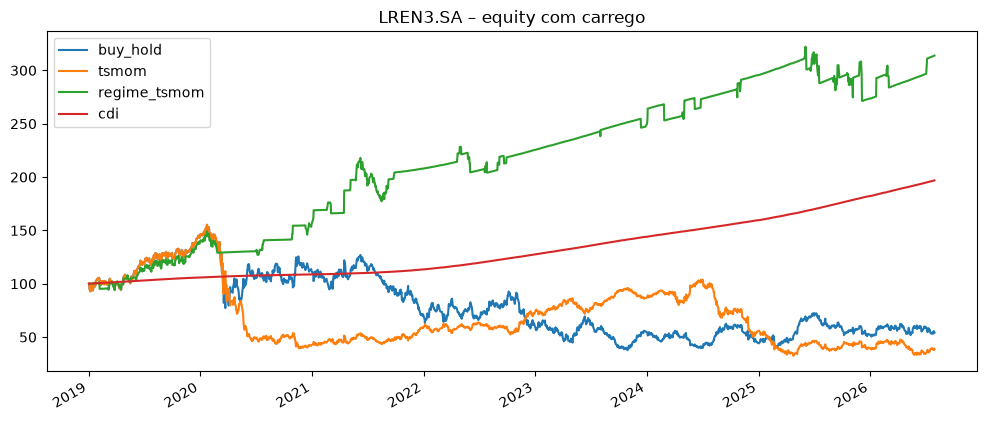

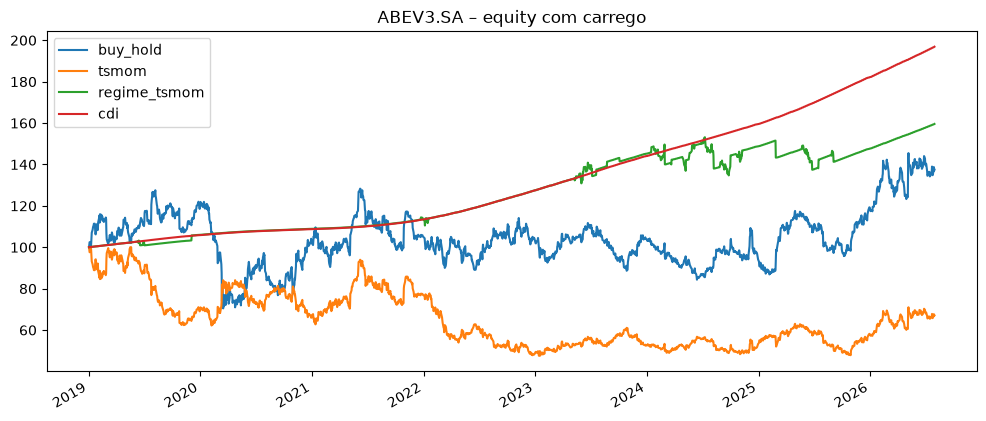

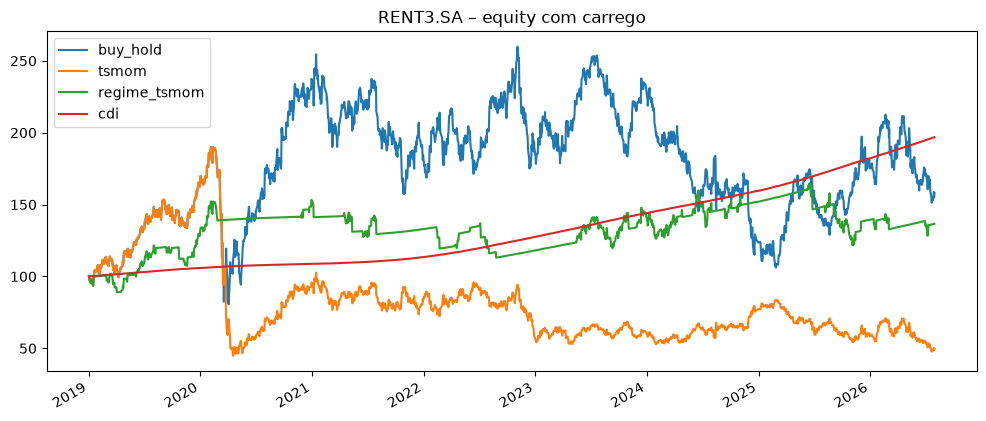

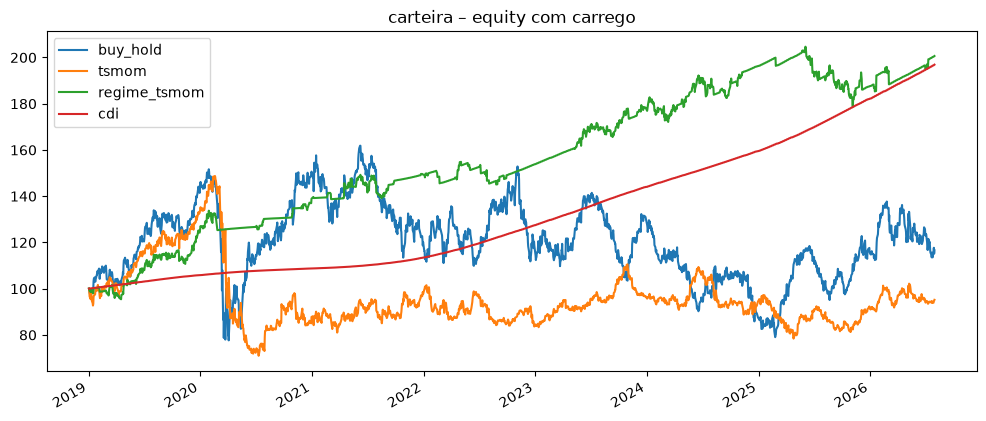

In [93]:
def curva(strat):
    r = pd.Series(strat.analyzers.ret_diario.get_analysis())
    r.index = pd.to_datetime(r.index)
    return 100 * (1 + r).cumprod()


for ativo in tickers + ["carteira"]:
    curvas = pd.DataFrame({nome: curva(resultados[(ativo, nome)][1]) for nome in estrategias})
    curvas["cdi"] = 100 * (1 + cdi_dia.reindex(curvas.index).fillna(0)).cumprod()
    curvas.plot(figsize=(12, 5), title=f"{ativo} – equity com carrego")
    plt.show()

In [94]:
tempo = pd.DataFrame({
    t: {
        "Alta vol – treino (%)": 100 * (regimes[t]["xi"].loc[:TRAIN_END] >= 0.5).mean(),
        "Alta vol – teste (%)": 100 * (regimes[t]["xi"].loc[TEST_START:] >= 0.5).mean(),
        "Trocas de regime – teste": int(((regimes[t]["xi"].loc[TEST_START:] >= 0.5).astype(int).diff().abs()).sum()),
    }
    for t in tickers
}).T.round(1)
tempo

,Alta vol – treino (%),Alta vol – teste (%),Trocas de regime – teste
LREN3.SA,45.9,77.6,124.0
ABEV3.SA,86.0,88.9,54.0
RENT3.SA,57.6,69.5,143.0
